# 01 · Guided-capture ROI (paper Sec. 2.1.2, Eq. 1–5, Fig. *image_capture*)

The app draws a fixed guide covering **α = 0.45** of the preview width, with the label's 5:3 aspect ratio.
This notebook maps that guide to image pixels and overlays it on a real capture.

| | |
|---|---|
| **Inputs** | `data/raw/table1_et/images/*.png` (one image used) |
| **Outputs** | `results/figures/fig_image_capture.png` |
| **Runtime** | < 5 s |

In [ ]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import visioncrack as vc
from visioncrack import io
np.set_printoptions(precision=3, suppress=True)
print('visioncrack', vc.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
FIG = io.results_dir('figures'); TAB = io.results_dir('tables')

visioncrack 0.1.0 | numpy 2.2.6 | pandas 2.3.0


## Eq. 1–5 for the Table 1 device
Preview 430 × 932 logical px, capture 2160 × 3840 px.

In [ ]:
SCREEN = (430, 932)
IMAGE = (2160, 3840)
roi = vc.preview_roi(IMAGE, SCREEN)
print(roi)
print(f'scale s = 50 mm / {roi.w} px = {vc.mm_per_px(roi.w):.5f} mm/px  ({1/vc.mm_per_px(roi.w):.2f} px/mm)')
assert (roi.x, roi.y, roi.w, roi.h) == (682, 2884, 797, 478)

Roi(x=682, y=2884, w=797, h=478)
scale s = 50 mm / 797 px = 0.06274 mm/px  (15.94 px/mm)


## Guide on screen vs. ROI on the captured image

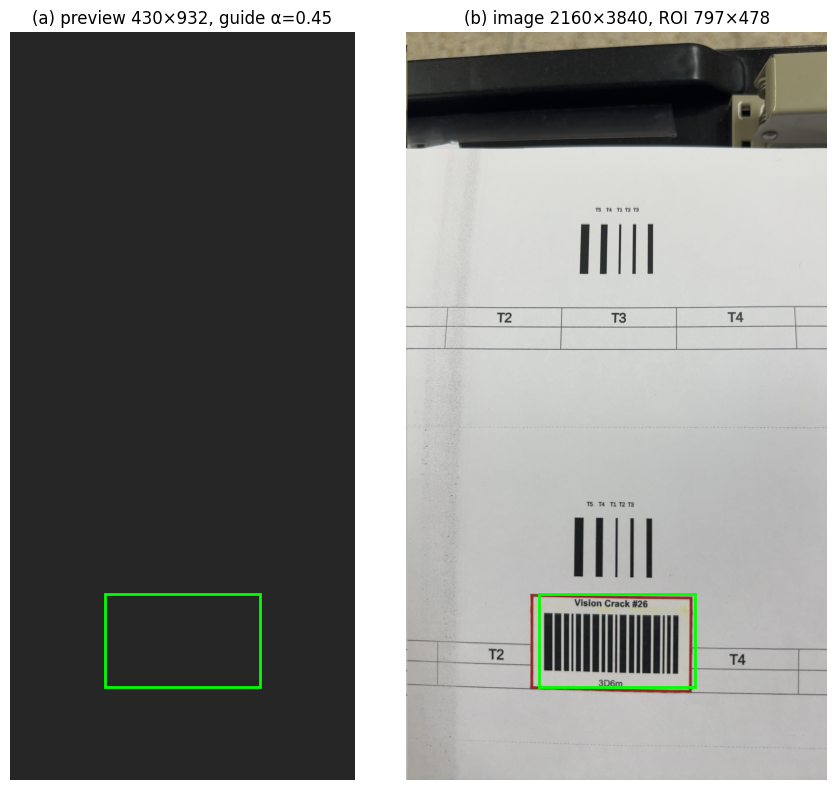

In [ ]:
from matplotlib.patches import Rectangle
caps, _ = vc.load_table1()
img = vc.read_rgb(caps.path[0])

sx = SCREEN[0] * 0.45; sh = 3 * sx / 5
screen_rect = ((SCREEN[0] - sx) / 2, SCREEN[1] - 2 * sh, sx, sh)

fig, (a, b) = plt.subplots(1, 2, figsize=(9, 8), gridspec_kw={'width_ratios': [1, 1]})
a.add_patch(Rectangle((0, 0), *SCREEN, fc='0.15'))
a.add_patch(Rectangle(screen_rect[:2], *screen_rect[2:], fc='none', ec='lime', lw=2))
a.set_xlim(0, SCREEN[0]); a.set_ylim(SCREEN[1], 0); a.set_aspect('equal')
a.set_title(f'(a) preview {SCREEN[0]}×{SCREEN[1]}, guide α=0.45')
b.imshow(img)
b.add_patch(Rectangle((roi.x, roi.y), roi.w, roi.h, fc='none', ec='lime', lw=2))
b.set_title(f'(b) image {IMAGE[0]}×{IMAGE[1]}, ROI {roi.w}×{roi.h}')
for ax in (a, b): ax.axis('off')
plt.tight_layout(); plt.savefig(FIG / 'fig_image_capture.png', dpi=200); plt.show()

## Zoom: detected barcode corners inside the ROI
Corners come from the app (`metadata.csv`, ROI coordinates).

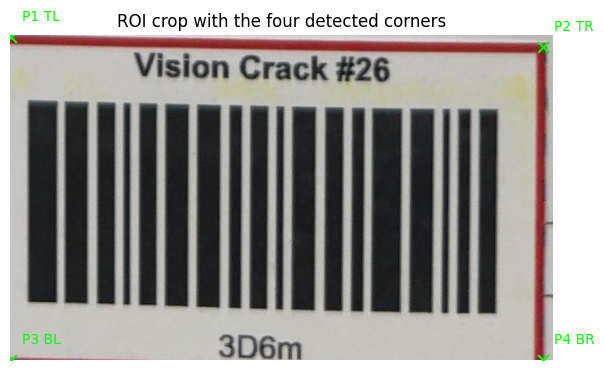

In [ ]:
x0, y0, x1, y1 = roi.xyxy
bb = caps.bbox[0]
plt.figure(figsize=(7, 4.5))
plt.imshow(img[y0:y1, x0:x1])
plt.scatter(bb[:, 0], bb[:, 1], c='lime', s=60, marker='x')
for (px, py), name in zip(bb, ['P1 TL', 'P2 TR', 'P3 BL', 'P4 BR']):
    plt.annotate(name, (px, py), color='lime', xytext=(8, 12), textcoords='offset points')
plt.axis('off'); plt.title('ROI crop with the four detected corners'); plt.show()